# スペクトルのフィッティング、積分
###  微分したようなスペクトルからバックグラウンドノイズを取り除いて処理する

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import integrate
from ipywidgets import interact
%matplotlib inline

In [12]:
plt.style.use("ggplot")

In [13]:
df = pd.read_excel("spectrum.xlsx", header=None)

In [14]:
df.head()

,0,1
0,349.0,-2.9678
1,349.1,1.7821
2,349.2,0.9071
3,349.3,0.7821
4,349.4,0.7196


In [15]:
df2 = df.rename(columns={0:"lambda", 1:"Intensity"})

In [16]:
df2.head()

,lambda,Intensity
0,349.0,-2.9678
1,349.1,1.7821
2,349.2,0.9071
3,349.3,0.7821
4,349.4,0.7196


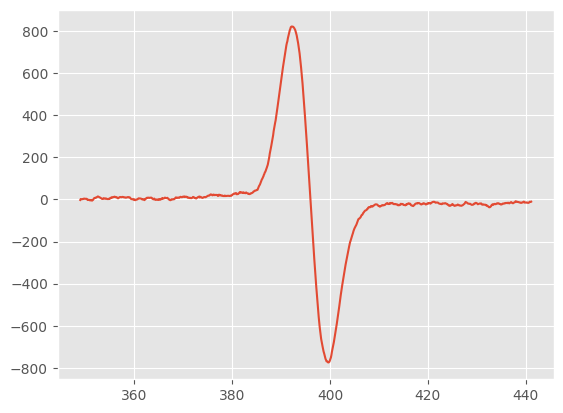

In [17]:
plt.plot(df2["lambda"], df2["Intensity"])

In [18]:
y_int = integrate.cumtrapz(df2["Intensity"], df2["lambda"], initial=0)

/var/folders/1x/rw8b928x6wsbjk3d2ddkkg5w0000gn/T/ipykernel_15110/2435300060.py:1: DeprecationWarning: 'scipy.integrate.cumtrapz' is deprecated in favour of 'scipy.integrate.cumulative_trapezoid' and will be removed in SciPy 1.14.0
  y_int = integrate.cumtrapz(df2["Intensity"], df2["lambda"], initial=0)


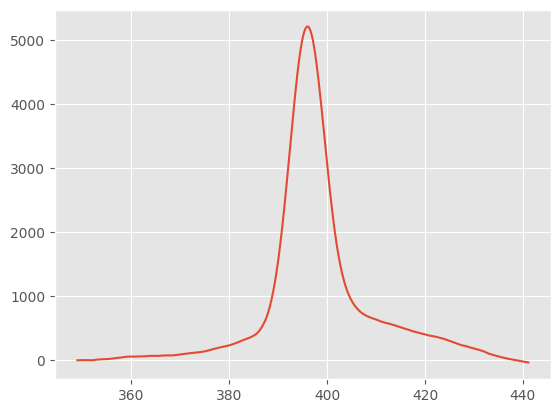

In [19]:
plt.plot(df2["lambda"], y_int)

ノイズのところから反映されてしまっているため、370あたりから上がってしまい、400を過ぎても下がりきっていない

# $y = e^{-\frac{(x-x_{0})^2}{2\sigma^2}}$

In [ ]:
@interact(Intensity=(0,800,3), x0=(360,420,0.5), sigma=(0,5,0.5))
def animation(Intensity, x0, sigma):
    plt.plot(df2["lambda"], df2["Intensity"])
    x = df2["lambda"]
    y = Intensity * (x0 - x) * np.exp(-0.5 * (x0 - x) ** 2 / sigma ** 2)
    plt.plot(x, y)
    plt.show()

interactive(children=(IntSlider(value=399, description='Intensity', max=800, step=3), FloatSlider(value=390.0,…

In [22]:
x = np.arange(350, 440, 0.001)
Intensity = 393
x0 = 396
sigma = 3.5
y = Intensity * (x0 - x) * np.exp(-0.5 * (x0 - x) ** 2 / sigma ** 2)

In [ ]:
y_int2 = integrate.cumtrapz(y, x, initial=0)

/var/folders/1x/rw8b928x6wsbjk3d2ddkkg5w0000gn/T/ipykernel_15110/3573512793.py:1: DeprecationWarning: 'scipy.integrate.cumtrapz' is deprecated in favour of 'scipy.integrate.cumulative_trapezoid' and will be removed in SciPy 1.14.0
  y_int2 = integrate.cumtrapz(y, x, initial=0)


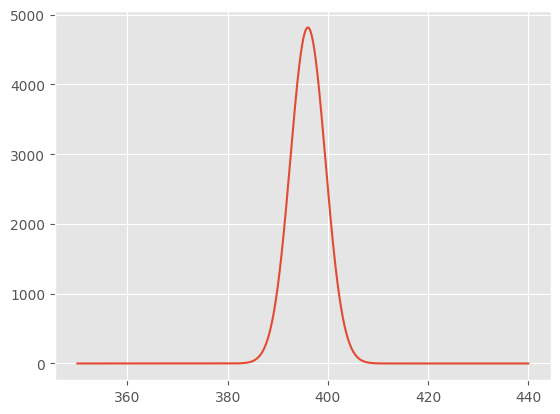

In [24]:
plt.plot(x, y_int2)

/var/folders/1x/rw8b928x6wsbjk3d2ddkkg5w0000gn/T/ipykernel_15110/1843288421.py:1: DeprecationWarning: 'scipy.integrate.cumtrapz' is deprecated in favour of 'scipy.integrate.cumulative_trapezoid' and will be removed in SciPy 1.14.0
  y_int3 = integrate.cumtrapz(y_int2, x, initial=0)


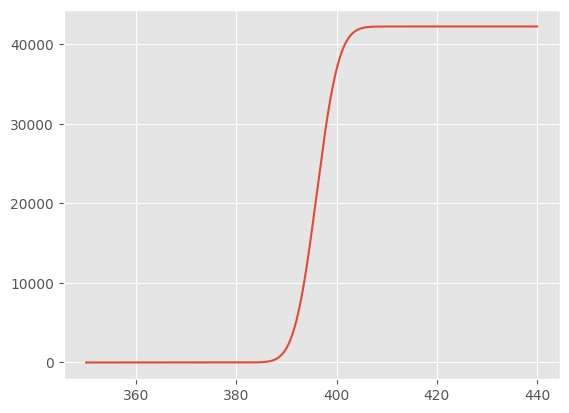

In [25]:
y_int3 = integrate.cumtrapz(y_int2, x, initial=0)
plt.plot(x, y_int3)

### スペクトルをフィッティングすることでノイズを除去し、真の面積を求めることが可能